# Ariketa 3.6 — Ensembleak: Random Forest eta Gradient Boosting 🌲🌲🚀 (EGITEKO)

Orain arte eredu **bakarrekin** lan egin dugu:

```text
Decision Tree
KNN
Logistic Regression
SVM
```

Orain ideia berri bat:

> **Zergatik erabili eredu bakar baten iritzia, eredu askoren informazioa konbina badezakegu?**

Horri **ensemble learning** deitzen zaio.

Saio honetan bi estrategia ikusiko ditugu:

```text
ENSEMBLEAK
│
├── BAGGING / RANDOM FOREST
│   ├─ zuhaitzak paraleloan / independenteago entrenatu
│   └─ amaieran BOZKETA
│
└── BOOSTING
    ├─ zuhaitzak sekuentzialki entrenatu
    └─ zuhaitz berriak aurreko ensemble-a hobetzen saiatzen dira
```

### Saioaren ibilbidea

```text
1. Bagging eta bootstrap
2. Random Forest
3. Zuhaitz bakarra vs basoa
4. Bozketa
5. Feature importance
6. Gradient Boosting
7. learning_rate + n_estimators
8. Random Forest vs Boosting
9. UD-ko ereduen azken konparazioa
```


## 📝 Nola egin

- 🟢 **EMANDA:** exekutatu eta ulertu.
- 🟡 **HUTSUNEAK BETE:** `____` osatu.
- 🔴 **KODETU ZEROTIK:** zati osoa idatzi.

Helburua ez da soilik accuracy handiagoa lortzea.

Helburua da ulertzea:

> **zergatik lagun dezake eredu asko konbinatzeak.**


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    recall_score
)


# 0 ATALA — Ensemble baten intuizioa 🟢

Pentsa 5 zuhaitzek bidaiari bati buruz hau esaten dutela:

```text
Tree 1 → bizirik
Tree 2 → bizirik
Tree 3 → hil
Tree 4 → bizirik
Tree 5 → hil
          ↓
        3 vs 2
          ↓
Random Forest → bizirik
```

Random Forest-en kasuan ideia nagusia:

> **zuhaitz askoren bozketa erabiltzea.**

Boosting-en filosofia desberdina da:

```text
Tree 1
  ↓
uneko errorea
  ↓
Tree 2-k hobetu
  ↓
geratzen den errorea
  ↓
Tree 3-k hobetu
  ↓
...
```

Beraz:

> **Random Forest = aniztasuna + bozketa**  
> **Boosting = hobekuntza sekuentziala**


# 1 ATALA — Bagging eta bootstrap 🟢

Random Forest ulertzeko lehenengo ideia **bootstrap sample** da.

Hemen `sample` hitzak bi esanahi nahas ditzake, beraz bereiziko ditugu:

```text
OBSERVATION / DATU-PUNTUA
→ errenkada bakarra
→ Titanic-en: BIDAIARI BAT

BOOTSTRAP SAMPLE
→ errenkada askorekin sortutako training multzo berria
→ Titanic-en: BIDAIARI MULTZO BERRI BAT
```

Beraz, Titanic-en **errenkada bakoitza bidaiari bat da**.

Demagun TRAIN multzo oso txiki batean 8 bidaiari ditugula:

```text
A  B  C  D  E  F  G  H
```

Random Forest-ek zuhaitz baterako training multzo berri bat sor dezake:

```text
A  C  C  D  F  H  H  B
```

Horixe da **bootstrap sample** bat.

## Zer esan nahi du `with replacement` / ordezkapenarekin?

Poltsa baten analogia:

```text
1. Bidaiari bat ausaz atera.
2. Training laginean apuntatu.
3. Bidaiaria BERRIRO poltsan sartu.
4. Hurrengo bidaiaria atera.
5. Errepikatu.
```

Horregatik bidaiari bera behin baino gehiagotan ager daiteke:

```text
C → 2 aldiz
H → 2 aldiz
```

eta beste batzuk ez dira agertzen:

```text
E → 0 aldiz
G → 0 aldiz
```

`RandomForestClassifier`-en ohiko konfigurazioan (`bootstrap=True`) zuhaitz bakoitzak horrelako bootstrap lagin propioa jasotzen du.

Ondorioa:

```text
TRAIN originala
      ↓
bootstrap sample 1 → Tree 1
bootstrap sample 2 → Tree 2
bootstrap sample 3 → Tree 3
...
```

> **Titanic-en errenkada bakoitza bidaiari bat da. Bootstrap lagina TRAIN-eko bidaiariak ausaz eta ordezkapenarekin aukeratuz sortutako training multzo berri bat da.**

Eta oso garrantzitsua:

> **Bootstrap TRAIN multzotik egiten da; TEST ez da erabiltzen zuhaitzak entrenatzeko.**


In [2]:
# Bootstrap ideia mini-adibide batekin.
# A, B, C... letra bakoitza TRAIN-eko errenkada / bidaiari bat dela pentsatu.

datuak = np.array(list("ABCDEFGH"))

# random_state baten antzeko ideia:
# emaitza errepikagarria izateko random generator finkoa.
rng = np.random.default_rng(42)

for zuhaitza in range(1, 4):

    # size=len(datuak):
    # bootstrap laginak jatorrizko TRAIN-en TAMAINA bera du.
    #
    # replace=True:
    # aukeratutako bidaiaria "poltsara itzultzen da";
    # beraz bidaiari bera berriro aukeratu daiteke.
    lagina = rng.choice(
        datuak,
        size=len(datuak),
        replace=True
    )

    print(f'Tree {zuhaitza}:', lagina)


Tree 1: ['A' 'G' 'F' 'D' 'D' 'G' 'A' 'F']
Tree 2: ['B' 'A' 'E' 'H' 'F' 'G' 'F' 'G']
Tree 3: ['E' 'B' 'G' 'D' 'E' 'C' 'B' 'H']


## 1.1 — Bigarren ausazkotasuna: feature-ak 🟢

Random Forest-ek **bi ausazkotasun mota** erabiltzen ditu:

```text
1. ZUHAITZ bakoitzerako:
   TRAIN-eko bootstrap sample desberdina

2. ZUHAITZAREN SPLIT bakoitzean:
   feature-en ausazko azpimultzo desberdina
```

### Lehenengo: zer da `split` bat?

`split` bat **ez da subtree bat**.

Decision Tree batean:

```text
                    ROOT NODE
              sex_male <= 0.5 ?
                  /           \
                bai            ez
                /               \
        pclass <= 2.5 ?       fare <= 30 ?
           /      \              /     \
         ...      ...          ...     ...
```

Galdera bakoitza split bat da:

```text
sex_male <= 0.5 ?  → split bat
pclass <= 2.5 ?    → beste split bat
fare <= 30 ?       → beste split bat
```

Definizio erabilgarriak:

```text
NODE
→ zuhaitzeko puntu bat

SPLIT
→ node horretan datuak bi adarretan banatzeko hartutako erabakia

SUBTREE
→ node bat + node horretatik beherako adar eta node guztiak
```

### Zer egiten du Random Forest-ek split bakoitzean?

Demagun feature hauek ditugula:

```text
pclass
age
fare
sex_male
embarked_Q
embarked_S
```

Decision Tree arrunt batek split bat aukeratzean feature guztiak azter ditzake.

Random Forest-ek, ordea, node batean ausaz aukeratutako feature batzuk soilik eskaintzen dizkio zuhaitzari:

```text
NODE 1

ausaz aukeratutako feature-ak:
age + sex_male
        ↓
bi horietatik Gini gehien murrizten duen
feature + threshold konbinazioa aukeratu
```

Hurrengo node batean **ausazko azpimultzo berri bat**:

```text
NODE 2

ausaz aukeratutako feature-ak:
fare + pclass
        ↓
horietatik split onena aukeratu
```

Eta hurrengo node batean berriro:

```text
NODE 3

beste feature azpimultzo ausazko bat
```

`RandomForestClassifier`-en default `max_features='sqrt'` da sailkapenean.

Gure Titanic input-ean 6 feature inguru baditugu:

```text
sqrt(6) ≈ 2
```

beraz split bakoitzean gutxi gorabehera **2 feature hautagai** aztertuko dira default konfigurazioarekin.

> **Random Forest-en zuhaitz bakoitzak bootstrap lagin desberdin bat jasotzen du, eta split bakoitzean feature-en ausazko azpimultzo berri bat aztertzen da.**

Horregatik basoko zuhaitzak ez dira guztiak berdinak.


# 2 ATALA — Titanic prestatzea 🟢🟡

Aurreko notebook-etako preprocessing araua mantenduko dugu:

> **Datuetatik parametro bat ikasten duen edozein urrats → TRAIN bakarrik.**

Beraz:

```text
RAW Titanic
↓
TRAIN / TEST
↓
TRAIN-etik age mediana + embarked moda
↓
balio berdinak aplikatu TRAIN eta TEST-en
↓
One-Hot Encoding
↓
bi bertsio prestatu:
    X_train / X_test       → Tree / RF / Boosting
    X_train_s / X_test_s   → KNN / Logistic / SVM
```

### Eskalatzeari buruz

```text
Decision Tree    → ez du behar
Random Forest    → ez du behar
GradientBoosting → ez du behar

KNN              → bai
Logistic         → gomendatua
SVM              → bai
```

Tree motako ereduei ez diegu scaling aplikatuko azken konparaketan.


In [3]:
# Colab-en internet konexioa behar du.
df = sns.load_dataset('titanic')

d = df[
    ['survived', 'pclass', 'sex', 'age', 'fare', 'embarked']
].copy()

print('Dataset shape:', d.shape)
d.head()


Dataset shape: (891, 6)


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


In [4]:
# 1. TRAIN / TEST egin LEHENENGO
train_df, test_df = train_test_split(
    d,
    test_size=0.2,
    random_state=42,
    stratify=d['survived']
)

train_df = train_df.copy()
test_df = test_df.copy()


# 2. TRAIN-etik bakarrik ikasi age mediana eta embarked moda
age_mediana = train_df['age'].median()
embarked_moda = train_df['embarked'].mode()[0]


# 3. Balio BERBERAK aplikatu TRAIN eta TEST-en
train_df['age'] = train_df['age'].fillna(age_mediana)
test_df['age'] = test_df['age'].fillna(age_mediana)

train_df['embarked'] = train_df['embarked'].fillna(embarked_moda)
test_df['embarked'] = test_df['embarked'].fillna(embarked_moda)


print('TRAIN:', len(train_df), '| TEST:', len(test_df))
print('TRAIN nuluak:', train_df.isnull().sum().sum())
print('TEST nuluak :', test_df.isnull().sum().sum())


TRAIN: 712 | TEST: 179
TRAIN nuluak: 0
TEST nuluak : 0


In [5]:
# Target
y_train = train_df['survived'].values
y_test = test_df['survived'].values


# Features
X_train = train_df.drop(columns=['survived'])
X_test = test_df.drop(columns=['survived'])


# One-Hot Encoding
X_train = pd.get_dummies(
    X_train,
    columns=['sex', 'embarked'],
    drop_first=True
)

X_test = pd.get_dummies(
    X_test,
    columns=['sex', 'embarked'],
    drop_first=True
)

# TEST-ek TRAIN-en zutabe berdinak + ordena bera
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train = X_train.astype(float)
X_test = X_test.astype(float)


# Scaling behar duten modeloentzako KOPIAK
X_train_s = X_train.copy()
X_test_s = X_test.copy()

num_cols = ['pclass', 'age', 'fare']

scaler = StandardScaler()

# bete ____ :
X_train_s[num_cols] = scaler.fit_transform(
    X_train[num_cols]
)

X_test_s[num_cols] = scaler.transform(
    X_test[num_cols]
)


print('Tree/RF/Boosting input:', X_train.shape)
print('KNN/Logistic/SVM input:', X_train_s.shape)
print(list(X_train.columns))


Tree/RF/Boosting input: (712, 6)
KNN/Logistic/SVM input: (712, 6)
['pclass', 'age', 'fare', 'sex_male', 'embarked_Q', 'embarked_S']


# 3 ATALA — Random Forest: baso bat, ez zuhaitz bat 🟡

`RandomForestClassifier`-en parametro garrantzitsu bat:

```python
n_estimators
```

hau da:

> **basoko zuhaitz kopurua.**

Adibidez:

```python
RandomForestClassifier(n_estimators=100)
```

→ 100 zuhaitzeko basoa.

Random Forest-ek zuhaitz askoren informazioa konbinatzen du azken sailkapena egiteko.

## Bi neurri erakutsiko ditugu

### Accuracy

```text
TEST bidaiari GUZTIETATIK
zenbat sailkatu ditu zuzen?
```

### Recall (`survived = 1`)

Zuek confusion matrix ezagutzen duzue. `survived=1` klasea positibotzat hartuta:

```text
TP → benetan bizirik + modeloak "bizirik"
FN → benetan bizirik + modeloak "hil"
```

Beraz:

\[
Recall=\frac{TP}{TP+FN}
\]

Galdera arruntean:

> **Benetan bizirik atera ziren bidaiarietatik, zenbat identifikatu ditu modeloak zuzen "bizirik" bezala?**

Adibidez, recall `0.725` balitz:

```text
≈ benetan bizirik atera zirenen %72.5 identifikatu ditu
```

Oraingoz nahikoa da interpretazio hori ulertzea; metrikak geroago landuko ditugu sakonago.


In [6]:
# n_estimators = basoko zuhaitz kopurua
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Random Forest tree-based modeloa da:
# EZ dugu scaling behar.
rf.fit(X_train, y_train)

# TEST multzorako azken klaseak.
rf_pred = rf.predict(X_test)

print(
    'Random Forest TEST accuracy:',
    round(accuracy_score(y_test, rf_pred), 3)
)

# survived=1 klasearen recall:
# benetan bizirik atera zirenen artean
# modeloak zenbat identifikatu dituen "bizirik" bezala.
print(
    "'bizirik' recall:",
    round(recall_score(y_test, rf_pred), 3)
)


Random Forest TEST accuracy: 0.821
'bizirik' recall: 0.725


## 3.1 — Zuhaitz bakarra vs Random Forest 🟢

Decision Tree sakon batek **variance handia** izan dezake:

```text
TRAIN pixka bat aldatu
        ↓
split batzuk aldatu
        ↓
zuhaitzaren egitura nahiko desberdina izan daiteke
```

Random Forest-en:

```text
bootstrap desberdinak
+
split bakoitzean feature hautagai desberdinak
        ↓
Tree 1    Tree 2    Tree 3    ...    Tree 100
        \    |       /
         informazioa konbinatu
                ↓
          azken prediction
```

Zuhaitz bakoitza ez da perfektua izan behar.

Helburua da:

> **zuhaitz askoren errore eta desberdintasunak konbinatuz emaitza egonkorragoa lortzea.**

Horregatik Random Forest-ek zuhaitz bakarraren **variance / overfitting joera murriztu ohi du**.

Kontuz:

> **Ez dugu esango “Random Forest-ek ez du overfitting egiten”.**  
> Egin dezake; baina zuhaitz bakar sakon bat baino egonkorragoa izaten da maiz.


In [7]:
# Zuhaitz bakarra.
# max_depth ez dugu mugatu:
# horrela zuhaitzak TRAIN datuak oso ondo "memorizatzeko" joera izan dezake.
tree = DecisionTreeClassifier(
    random_state=42
)

tree.fit(X_train, y_train)

print('Decision Tree:')
print('  TRAIN:', round(tree.score(X_train, y_train), 3))
print('  TEST :', round(tree.score(X_test, y_test), 3))

print('\nRandom Forest:')
print('  TRAIN:', round(rf.score(X_train, y_train), 3))
print('  TEST :', round(rf.score(X_test, y_test), 3))


Decision Tree:
  TRAIN: 0.982
  TEST : 0.827

Random Forest:
  TRAIN: 0.982


  TEST : 0.821


### 3.1.1 — Ikus dezagun: zuhaitz bakarra vs basoko hainbat zuhaitz

Lehenengo, Decision Tree bakarraren **lehen 3 mailak** ikusiko ditugu.

Ondoren, Random Forest-eko **3 zuhaitz desberdinen lehen 2 mailak**.

Begiratu galdera hauei:

1. Root split bera al dute Random Forest-eko hiru zuhaitzek?
2. Feature berdinak erabiltzen al dituzte?
3. Threshold berdinak al dituzte?
4. Zergatik dira desberdinak?

Espero dugun azalpena:

```text
bootstrap sample desberdinak
+
split bakoitzeko feature hautagai ausazkoak
=
zuhaitz desberdinak
```

> `plot_tree(..., max_depth=2)` erabiltzeak EZ du esan nahi zuhaitza depth=2-rekin entrenatu denik. Grafikoan lehen mailak bakarrik erakusten ari gara, irakurgarria izan dadin.


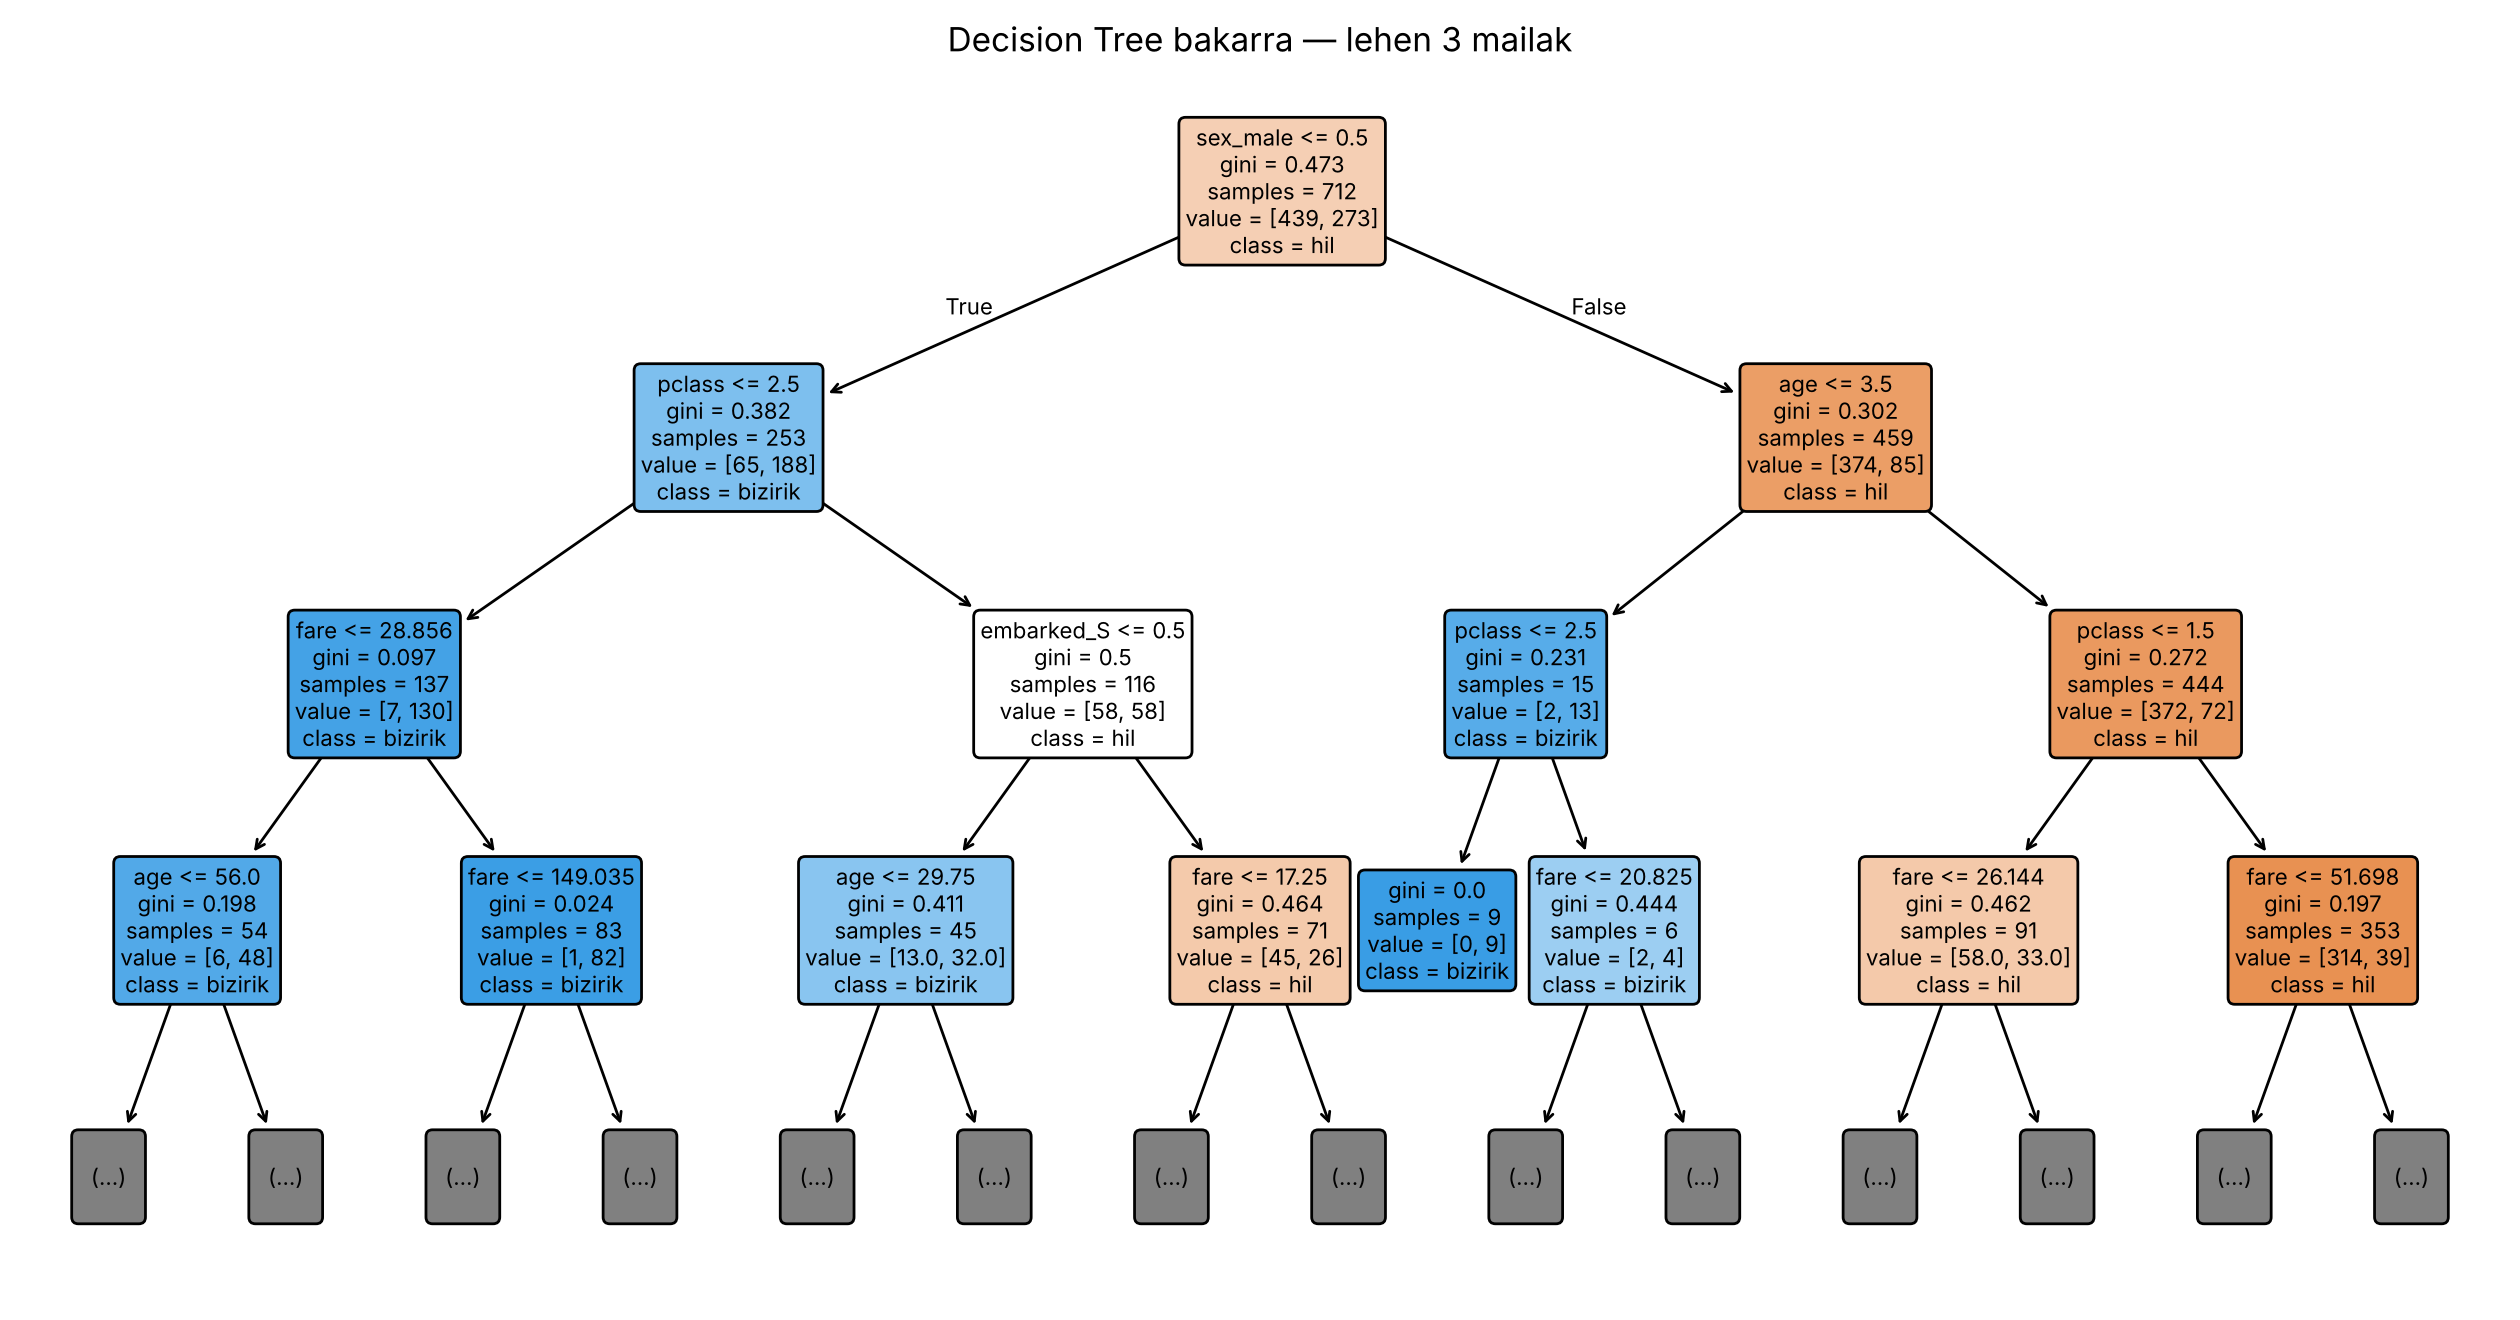

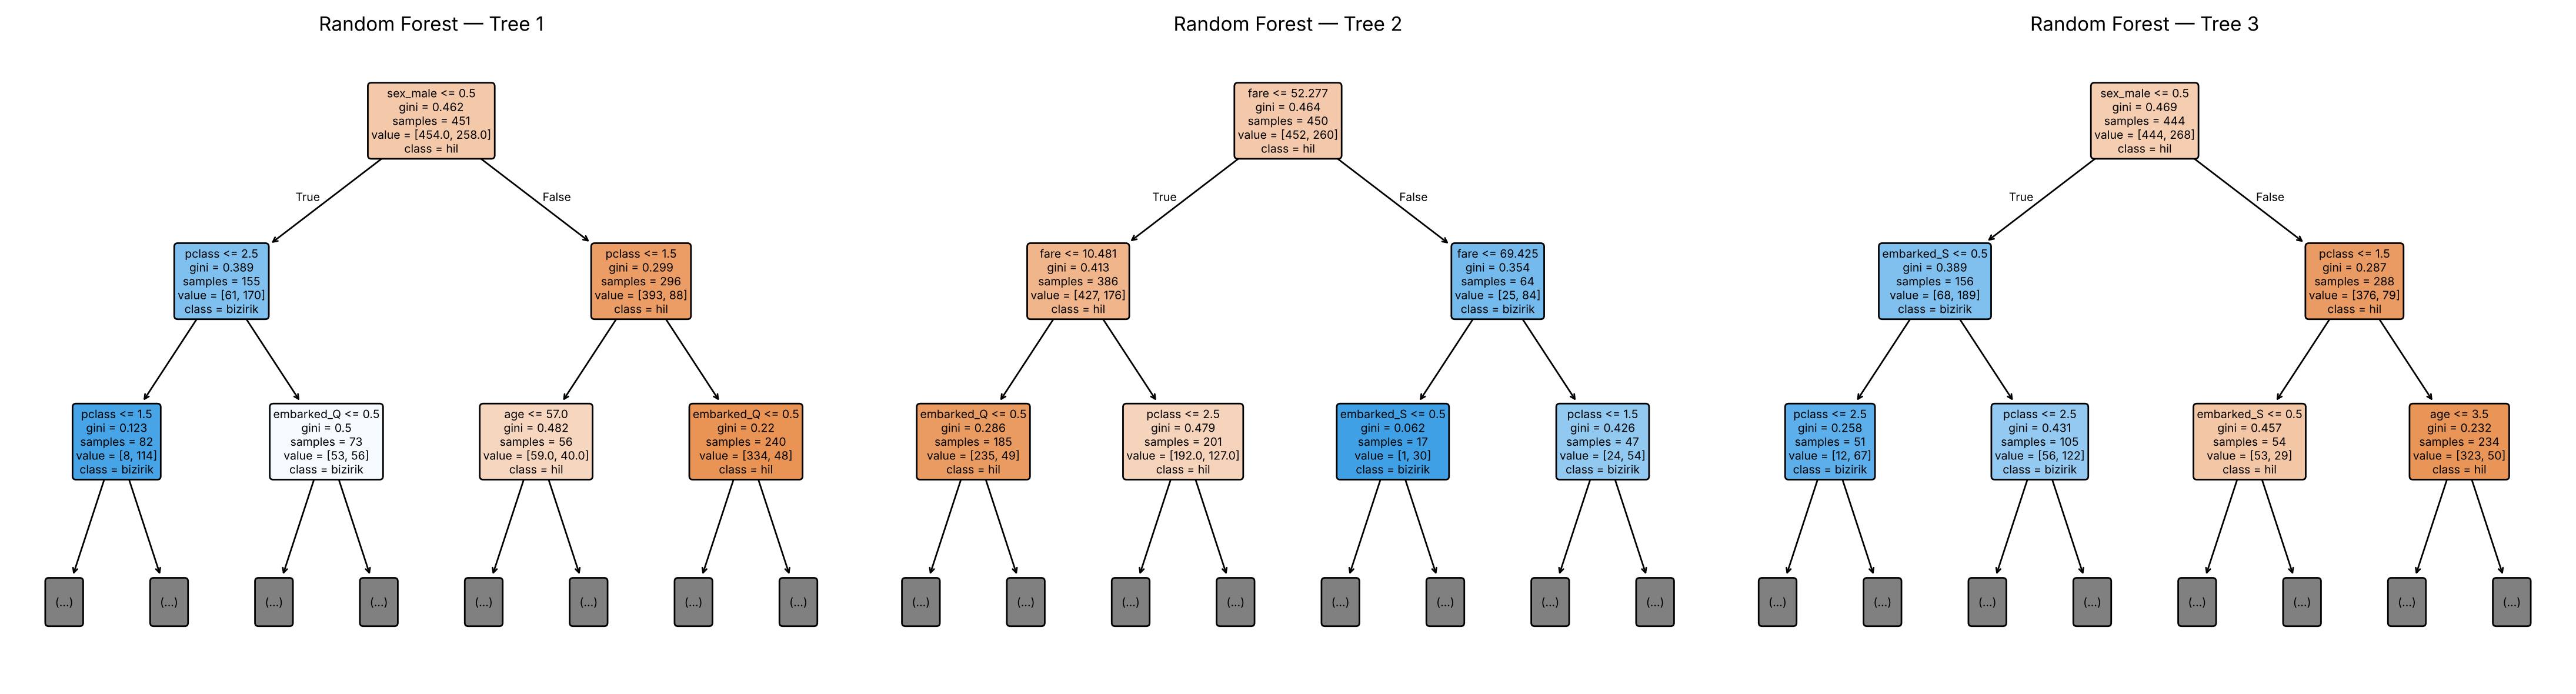

In [8]:
from sklearn.tree import plot_tree

# ------------------------------------------------------------
# 1) DECISION TREE BAKARRA
# ------------------------------------------------------------
plt.figure(figsize=(16, 8))

plot_tree(
    tree,
    feature_names=X_train.columns,
    class_names=['hil', 'bizirik'],
    filled=True,
    rounded=True,
    max_depth=3,     # BISTARATZEKO muga bakarrik
    fontsize=8
)

plt.title('Decision Tree bakarra — lehen 3 mailak')
plt.show()


# ------------------------------------------------------------
# 2) RANDOM FOREST-EKO 3 ZUHAITZ
# ------------------------------------------------------------
# Basoko zuhaitz guztiak erakustea ez litzateke irakurgarria.
# Horregatik lehenengo 3 zuhaitzak aukeratzen ditugu.
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

for i, ax in enumerate(axes):

    plot_tree(
        rf.estimators_[i],
        feature_names=X_train.columns,
        class_names=['hil', 'bizirik'],
        filled=True,
        rounded=True,
        max_depth=2,     # BISTARATZEKO muga bakarrik
        fontsize=7,
        ax=ax
    )

    ax.set_title(f'Random Forest — Tree {i + 1}')

plt.tight_layout()
plt.show()


**Erantzunak (3.1.1):**

1. **Ez.** Tree 1 eta Tree 3-k `sex_male <= 0.5` dute root-ean, baina **Tree 2-k `fare <= 52.28`**.
2. **Ez guztiak.** Feature batzuk errepikatzen dira (sex_male, pclass), baina bigarren mailan desberdinak agertzen dira: Tree 1 → pclass/pclass, Tree 2 → fare/fare, Tree 3 → embarked_S/pclass.
3. **Ez beti.** Feature bera dutenean ere (adib. `sex_male` 0.5, aldagai bitarra), beste split-etako atalaseak desberdinak dira (fare 10.48, 52.28, 69.43...).
4. Bi ausazkotasun mota direlako: zuhaitz bakoitzak **bootstrap lagin desberdina** jasotzen du (bidaiari desberdinak, batzuk errepikatuta), eta **split bakoitzean feature-en azpimultzo ausazko bat** bakarrik aztertzen du (`max_features='sqrt'` → ~2 hautagai). Adibidez, Tree 2-ren root-ean `sex_male` ez zegoen hautagaien artean, eta horregatik `fare` aukeratu zuen.

## 3.2 — Bozketa benetan ikusi 🟢

Aurreko bertsioan TEST-eko lehen bidaiaria erabiltzen genuen. Baina gerta daiteke lehen 5 zuhaitzek denek `0` edo denek `1` esatea.

Hori zuzena da, baina **ez da ensemble ideia erakusteko adibiderik onena**.

Orain kodeak automatikoki bilatuko du TEST-eko bidaiari bat non lehen 5 zuhaitzak **ez dauden guztiz ados**.

Adibidez:

```text
Tree 0 → 0
Tree 1 → 1
Tree 2 → 0
Tree 3 → 1
Tree 4 → 0
```

Hor ikusten dugu:

> **zuhaitz desberdinek iritzi desberdinak izan ditzakete.**

Ondoren Random Forest osoaren prediction-a ikusiko dugu.

### Ohar teknikoa

Ikasteko, “zuhaitzek bozkatzen dute” esatea oso intuizio ona da.

Scikit-learn-en `RandomForestClassifier.predict()`-ek, zehazki, zuhaitzen **class probability-ak batezbestekotu** eta probabilitate handiena duen klasea aukeratzen du.

Oraingoz gorde ideia hau:

> **Random Forest = zuhaitz askoren informazioa konbinatu → azken erabakia.**


In [9]:
# Zenbat zuhaitzen iragarpena erakutsi nahi dugu?
n_erakutsi = 5

aukeratutako_posizioa = None
bozkak = None

# TEST bidaiariak banan-banan aztertzen ditugu,
# lehen 5 zuhaitzen artean desadostasun bat aurkitu arte.
for pos in range(len(X_test)):

    hautagaia = X_test.iloc[[pos]]

    hautagai_boztak = [
        int(zuhaitza.predict(hautagaia.values)[0])
        for zuhaitza in rf.estimators_[:n_erakutsi]
    ]

    # set(...) multzoak balio desberdinak gordetzen ditu.
    #
    # len(set(...)) > 1
    # → 0 eta 1 agertzen dira
    # → zuhaitzak ez daude guztiz ados.
    if len(set(hautagai_boztak)) > 1:
        aukeratutako_posizioa = pos
        bozkak = hautagai_boztak
        break


# Oso kasu arraroan lehen 5 zuhaitzek TEST guztian bat egingo balute,
# lehen bidaiaria erabiliko genuke fallback gisa.
if aukeratutako_posizioa is None:

    aukeratutako_posizioa = 0
    bidaiaria = X_test.iloc[[0]]

    bozkak = [
        int(zuhaitza.predict(bidaiaria.values)[0])
        for zuhaitza in rf.estimators_[:n_erakutsi]
    ]

else:
    bidaiaria = X_test.iloc[[aukeratutako_posizioa]]


print('TEST posizioa:', aukeratutako_posizioa)
print()

# Aukeratutako bidaiariaren feature-ak ikusi.
display(bidaiaria)

print()

# Lehen 5 zuhaitzen hard prediction-ak.
for i, botoa in enumerate(bozkak):
    print(f'Tree {i}: {botoa}')

print('\nLehen 5 zuhaitzen prediction-ak:', bozkak)

# Baso OSOAREN prediction-a.
print(
    'Random Forest osoa:',
    int(rf.predict(bidaiaria)[0])
)

# Benetako etiketa.
print(
    'Benetako klasea  :',
    int(y_test[aukeratutako_posizioa])
)


TEST posizioa: 5



,pclass,age,fare,sex_male,embarked_Q,embarked_S
559,3.0,36.0,17.4,0.0,0.0,1.0



Tree 0: 1
Tree 1: 1
Tree 2: 1
Tree 3: 0
Tree 4: 0

Lehen 5 zuhaitzen prediction-ak: [1, 1, 1, 0, 0]
Random Forest osoa: 0
Benetako klasea  : 1


**Bozketaren interpretazioa:** lehen 5 zuhaitzetatik 3k `1` esan dute eta 2k `0`, baina **baso osoak `0`** iragarri du. Ez dago kontraesanik: baso osoak **100 zuhaitz** ditu, eta `predict()`-ek guztien probabilitateak batezbestekotzen ditu, ez soilik lehen 5en botoak. Kasu honetan benetako klasea `1` zen: zuhaitz bakar batzuk asmatu dute baina basoak ez — ensemble-ak ez du kasu bakoitza asmatzen, **batez beste** egonkorragoa da.

# 4 ATALA — Feature importance 🟡

`RandomForestClassifier`-ek hau eskaintzen du:

```python
rf.feature_importances_
```

Baina **nondik ateratzen dira zenbaki horiek?**

Ez da Random Forest-ek “asmaturiko” puntuazio misteriotsu bat.

Zuek Decision Tree-n ikasitako **Gini impurity**-rekin lotuta dago.

---

## 4.0.1 — Split batek impurity zenbat murrizten duen

Demagun node batean:

```text
Gini parent = 0.48
```

split egin ondoren, bi child node-en weighted impurity:

```text
Gini after = 0.30
```

Orduan split horrek lortu duen hobekuntza:

```text
0.48 - 0.30 = 0.18
```

Hau da:

> **split horrek impurity 0.18 murriztu du.**

Baina beste gauza bat ere kontuan hartzen da:

> **zenbat training sample / bidaiari iritsi diren node horretara.**

Root-eko split batek, adibidez, bidaiari asko eragiten ditu.

Zuhaitzaren behealdeko node txiki batek, agian, 20 bidaiari bakarrik.

Horregatik, kontzeptualki:

\[
\text{node contribution}
=
\text{node-ra iristen diren sample-en pisua}
\times
\text{impurity reduction}
\]

Formula zehatzago baten intuizioa:

\[
\frac{N_{node}}{N}
\left(
Gini_{parent}
-
\frac{N_L}{N_{node}}Gini_L
-
\frac{N_R}{N_{node}}Gini_R
\right)
\]

Ez duzue formula hau memorizatu behar.

Gorde hau:

> **Split batek Gini asko murrizten badu ETA sample asko eragiten baditu, feature horrek importance handiagoa jasoko du.**

---

## 4.0.2 — Feature bera hainbat split-etan erabil daiteke

Adibide sinplifikatua:

```text
sex_male:
    root split baten ekarpena     → 0.18
    beste split baten ekarpena    → 0.03
                                   ----
                                   0.21

pclass:
    split baten ekarpena          → 0.10
    beste split baten ekarpena    → 0.04
                                   ----
                                   0.14

age:
    hainbat split                 → 0.08

fare:
    hainbat split                 → 0.05
```

Zuhaitz batean feature berak sortutako ekarpen guztiak batu egiten dira.

Ondoren importance-ak normalizatzen dira.

Horregatik zuhaitz baten:

```python
tree.feature_importances_
```

balioen batura ≈ `1.0`.

---

## 4.0.3 — Eta Random Forest batean?

Orain ez dugu zuhaitz bakarra:

```text
Tree 1 → bere feature importance-ak
Tree 2 → bere feature importance-ak
Tree 3 → bere feature importance-ak
...
Tree 100 → bere feature importance-ak
```

Random Forest-ek zuhaitz guztietako informazioa konbinatzen du eta azken importance normalizatuak ematen ditu.

Beraz, honela pentsa dezakegu:

```text
split bakoitzeko impurity reduction
        ↓
feature bakoitzeko ekarpenak batu
        ↓
zuhaitz bakoitzean
        ↓
basoko zuhaitz guztietan konbinatu / batezbestekotu
        ↓
normalizatu
        ↓
rf.feature_importances_
```

Adibidez:

```text
sex_male = 0.35
```

EZ du esan nahi:

> “sex-ek biziraupenaren %35 azaltzen du”.

Interpretazio hobea:

> **Basoko impurity reduction normalizatuaren zati handi bat `sex_male` erabiltzen zuten split-ek sortu dute.**

### Bi ohar oso garrantzitsu

> **Feature importance ≠ kausalitatea.**

Feature bat prediction-erako erabilgarria izateak ez du esan nahi emaitzaren kausa denik.

Eta:

> impurity-based importance-ak feature jarraituak edo balio/threshold aukera asko dituzten feature-ak mesedetu ditzake.

Beraz, **orientazio gisa** erabiliko dugu, ez egia absolutu gisa.


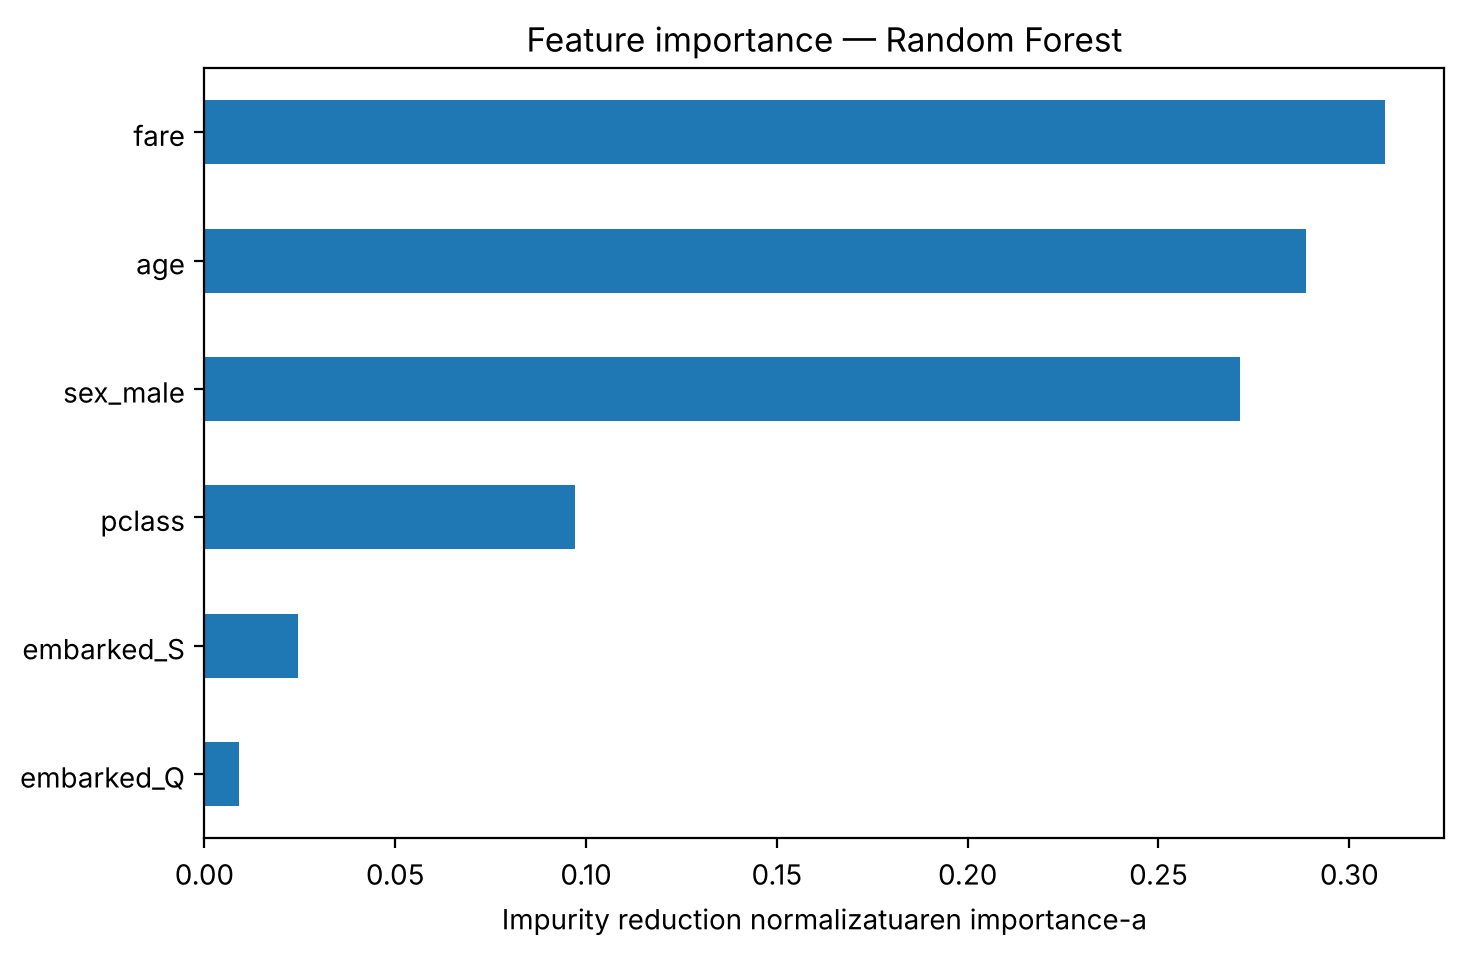

In [10]:
# Zein atributuk gordetzen ditu Random Forest-eko
# feature importance normalizatuak?
garrantzia = pd.Series(
    rf.feature_importances_,
    index=X_train.columns
).sort_values()

# Zein grafiko mota erabiliko dugu barra horizontaletarako?
garrantzia.plot(
    kind='barh',
    figsize=(8, 5)
)

plt.title(
    'Feature importance — Random Forest'
)
plt.xlabel(
    'Impurity reduction normalizatuaren importance-a'
)
plt.show()


### 4.0.4 — Zuhaitz bakar baten importance-ak vs baso osoarenak

Hurrengo kodeak bi gauza erakusten ditu:

```text
Tree 1 importance
vs
Random Forest importance
```

Espero da ez izatea berdinak, Tree 1 basoko zuhaitz bakarra baita.

Amaieran egiaztatuko dugu Random Forest importance-en batura ≈ `1.0` dela.


In [11]:
tree1_importance = pd.Series(
    rf.estimators_[0].feature_importances_,
    index=X_train.columns,
    name='Tree 1'
)

forest_importance = pd.Series(
    rf.feature_importances_,
    index=X_train.columns,
    name='Random Forest'
)

importance_konparaketa = pd.concat(
    [tree1_importance, forest_importance],
    axis=1
)

display(
    importance_konparaketa.sort_values(
        'Random Forest',
        ascending=False
    )
)

print(
    'Random Forest importance-en batura:',
    round(rf.feature_importances_.sum(), 6)
)


,Tree 1,Random Forest
fare,0.256118,0.309447
age,0.298549,0.288595
sex_male,0.300821,0.271412
pclass,0.103993,0.097072
embarked_S,0.023041,0.024425
embarked_Q,0.017479,0.009049


Random Forest importance-en batura: 1.0


## 4.1 — 🔴 Erronka: zenbat zuhaitz behar dira?

Probatu:

```text
1, 5, 10, 25, 50, 100, 200
```

eta marraztu:

```text
TRAIN accuracy
TEST accuracy
```

Galdera:

> **Zuhaitz gehiago gehitzean TEST emaitza egonkortzen al da?**

Random Forest-en zuhaitz gehiago gehitzeak kalkulu gehiago eskatzen du, baina normalean ez du Boosting-en moduan zuhaitz berri bakoitzarekin aurreko errorea sekuentzialki “jarraitzen”.


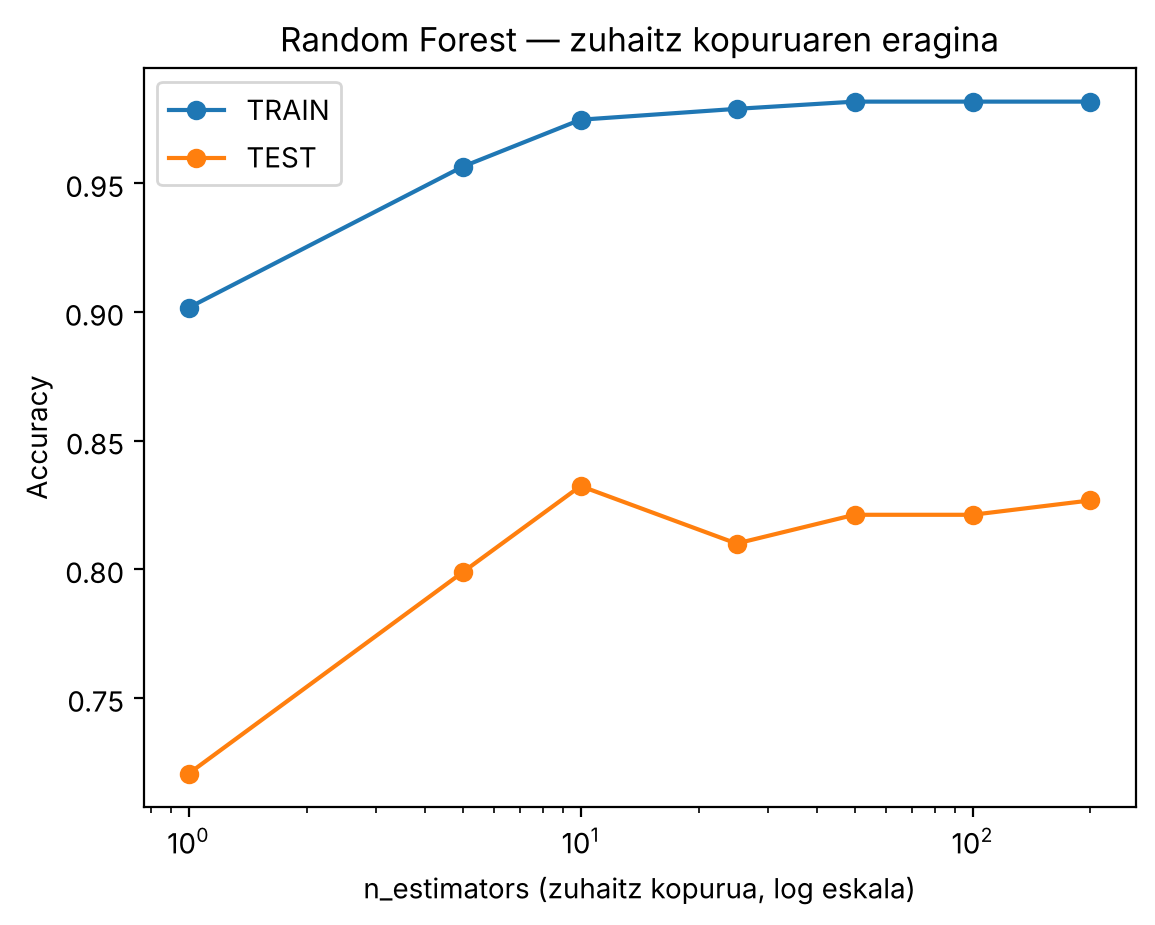

n_estimators=  1  TRAIN=0.902  TEST=0.721
n_estimators=  5  TRAIN=0.956  TEST=0.799
n_estimators= 10  TRAIN=0.975  TEST=0.832
n_estimators= 25  TRAIN=0.979  TEST=0.810
n_estimators= 50  TRAIN=0.982  TEST=0.821
n_estimators=100  TRAIN=0.982  TEST=0.821
n_estimators=200  TRAIN=0.982  TEST=0.827


In [12]:
# Zenbat zuhaitz behar dira?
zuhaitz_kopuruak = [1, 5, 10, 25, 50, 100, 200]

train_ak = []
test_ak = []

for n in zuhaitz_kopuruak:
    modeloa = RandomForestClassifier(n_estimators=n, random_state=42)
    modeloa.fit(X_train, y_train)           # tree-based -> scaling gabe
    train_ak.append(modeloa.score(X_train, y_train))
    test_ak.append(modeloa.score(X_test, y_test))

plt.plot(zuhaitz_kopuruak, train_ak, marker='o', label='TRAIN')
plt.plot(zuhaitz_kopuruak, test_ak, marker='o', label='TEST')
plt.xscale('log')
plt.xlabel('n_estimators (zuhaitz kopurua, log eskala)')
plt.ylabel('Accuracy')
plt.title('Random Forest — zuhaitz kopuruaren eragina')
plt.legend()
plt.show()

for n, tr, te in zip(zuhaitz_kopuruak, train_ak, test_ak):
    print(f'n_estimators={n:3d}  TRAIN={tr:.3f}  TEST={te:.3f}')

**Erantzuna (4.1):** **Bai, egonkortu egiten da.** Zuhaitz 1ekin TEST = 0.721 da (zuhaitz bakar bat, bootstrap batekin). 5–10 zuhaitzekin azkar igotzen da (0.799 → 0.832), eta **25etik aurrera 0.81–0.83 artean egonkortzen** da. TRAIN ere ~0.98-n geratzen da. Zuhaitz gehiago gehitzeak ez du overfitting-a handitzen (Boosting-ean ez bezala), baina hobekuntza ere ez da nabarmena: kalkulu-denbora gehiago bakarrik.

# 5 ATALA — Boosting: beste ensemble filosofia bat 🚀

Random Forest eta Gradient Boosting-ek zuhaitz asko erabiltzen dituzte, baina **oso filosofia desberdina** dute.

Random Forest:

```text
Tree 1 ─┐
Tree 2 ─┼──► informazioa konbinatu
Tree 3 ─┘
```

Zuhaitzak independenteago entrenatzen dira.

Gradient Boosting:

```text
hasierako modeloa
      ↓
prediction + loss
      ↓
Tree 1 gehitu
      ↓
prediction + loss berriro
      ↓
Tree 2 gehitu
      ↓
prediction + loss berriro
      ↓
Tree 3 gehitu
      ↓
...
```

## Logistic Regression-ekin lotura

Hau oso lotura interesgarria da, Logistic Regression-en dagoeneko gradient-aren ideia ikusi dugulako.

### Logistic Regression

Modeloa:

\[
z=b+w_1x_1+w_2x_2+\dots+w_nx_n
\]

eta, kontzeptualki:

```text
PREDICT
↓
Log Loss
↓
gradient
↓
w eta b UPDATE
↓
repeat
```

Iterazioz iterazio **ereduaren egitura bera** mantentzen da:

```text
sigmoid(w·x + b)
```

aldatzen direnak:

```text
w1, w2, ..., wn eta b
```

dira.

### Gradient Boosting

Gradient Boosting-en ere **loss** eta **gradient** ideia erabiltzen dira.

Baina ez dugu Logistic Regression-eko:

```text
w1, w2, ..., wn, b
```

koefiziente-bektore bera iterazioz iterazio eguneratzen.

Horren ordez:

```text
uneko ensemble-a
↓
loss-a kalkulatu
↓
loss-a murrizteko behar den norabidea / errore-seinalea
↓
zuhaitz berri bat entrenatu seinale hori modelatzeko
↓
zuhaitz hori ensemble-ari GEHITU
↓
repeat
```

Beraz, esaldi garrantzitsua:

> **Logistic Regression-en gradientearen bidez koefizienteak eguneratzen ditugu. Gradient Boosting-en gradientearen bidez hurrengo zuhaitzak zer zuzendu behar duen gidatzen dugu.**

Matematikoki, intuizio oso erabilgarria:

\[
F_{new}(x)=F_{old}(x)+\eta\cdot h_{new}(x)
\]

non:

```text
F_old    → orain arteko ensemble-a
h_new    → zuhaitz berriak ikasitako zuzenketa
η        → learning_rate
F_new    → ensemble berria
```

Ez duzue formula hau garatu behar; ideia ulertzeko da.

### Kontuz “akatsak zuzentzen ditu” esaldiarekin

Hasierako intuizio ona da:

> “zuhaitz berriak aurreko akatsak zuzentzen saiatzen dira”.

Baina `GradientBoostingClassifier`-en zehatzago:

> **zuhaitz berriak loss funtzioaren gradienteari lotutako pseudo-residual / errore-seinalea modelatzen saiatzen dira.**

Hau ez da soilik:

```text
gaizki sailkatutako errenkadak hartu
eta berriro entrenatu
```

(`AdaBoost`-en intuizioa horretara hurbilago dago).

Gure mailan gorde:

> **Boosting = uneko modeloa → loss → zuhaitz berri batekin zuzenketa → errepikatu.**


## 5.1 — Gradient Boosting entrenatu: `n_estimators` eta `learning_rate` 🟡

Bi parametro nagusi:

```text
n_estimators
→ zenbat boosting etapa / zuhaitz gehituko diren

learning_rate
→ zuhaitz berri bakoitzaren ekarpena zenbat murrizten den
```

Adibidez, zuhaitz berri batek kontzeptualki:

```text
+0.40
```

zuzenketa proposatzen badu:

```text
learning_rate = 1.0
→ +0.40 inguruko ekarpena

learning_rate = 0.1
→ +0.04 inguruko ekarpena
```

Horregatik:

```text
learning_rate HANDIA
→ zuzenketa handiagoak
→ azkarrago doitzen da
→ overfitting arrisku handiagoa izan daiteke

learning_rate TXIKIA
→ zuzenketa txikiagoak
→ normalean etapa / zuhaitz gehiago behar
→ ikasketa motelago eta leunagoa
```

Hau aurreko Logistic Regression-eko `η` learning rate ideiarekin konektatzen da:

```text
Logistic Regression:
parametroen UPDATE tamaina kontrolatu

Gradient Boosting:
zuhaitz berriaren EKARPEN tamaina kontrolatu
```

Oharra:

> `GradientBoostingClassifier`-en zuhaitzak normalean zuhaitz txikiak dira; zuhaitz bakoitzak ez du problema osoa bakarrik konpondu behar.


In [13]:
# n_estimators  → boosting etapa / zuhaitz kopurua
# learning_rate → zuhaitz berri bakoitzaren ekarpenaren tamaina
boost = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Gradient Boosting tree-based da:
# scaling EZ da behar.
boost.fit(X_train, y_train)

boost_pred = boost.predict(X_test)

print(
    'Gradient Boosting TEST accuracy:',
    round(accuracy_score(y_test, boost_pred), 3)
)


Gradient Boosting TEST accuracy: 0.799


## 5.2 — `n_estimators`-en eragina Boosting-en 🟡

Probatu zuhaitz/etapa kopuru desberdinak:

```text
10, 25, 50, 100, 200
```

`learning_rate = 0.1` finkoarekin.

Marraztuko dugu:

```text
TRAIN accuracy
TEST accuracy
```

Galdera:

> **Boosting gero eta gehiago entrenatzeak TEST emaitza beti hobetzen al du?**

Ez derrigorrez.

Boosting sekuentziala denez, gehiegi doituz overfitting ager daiteke.


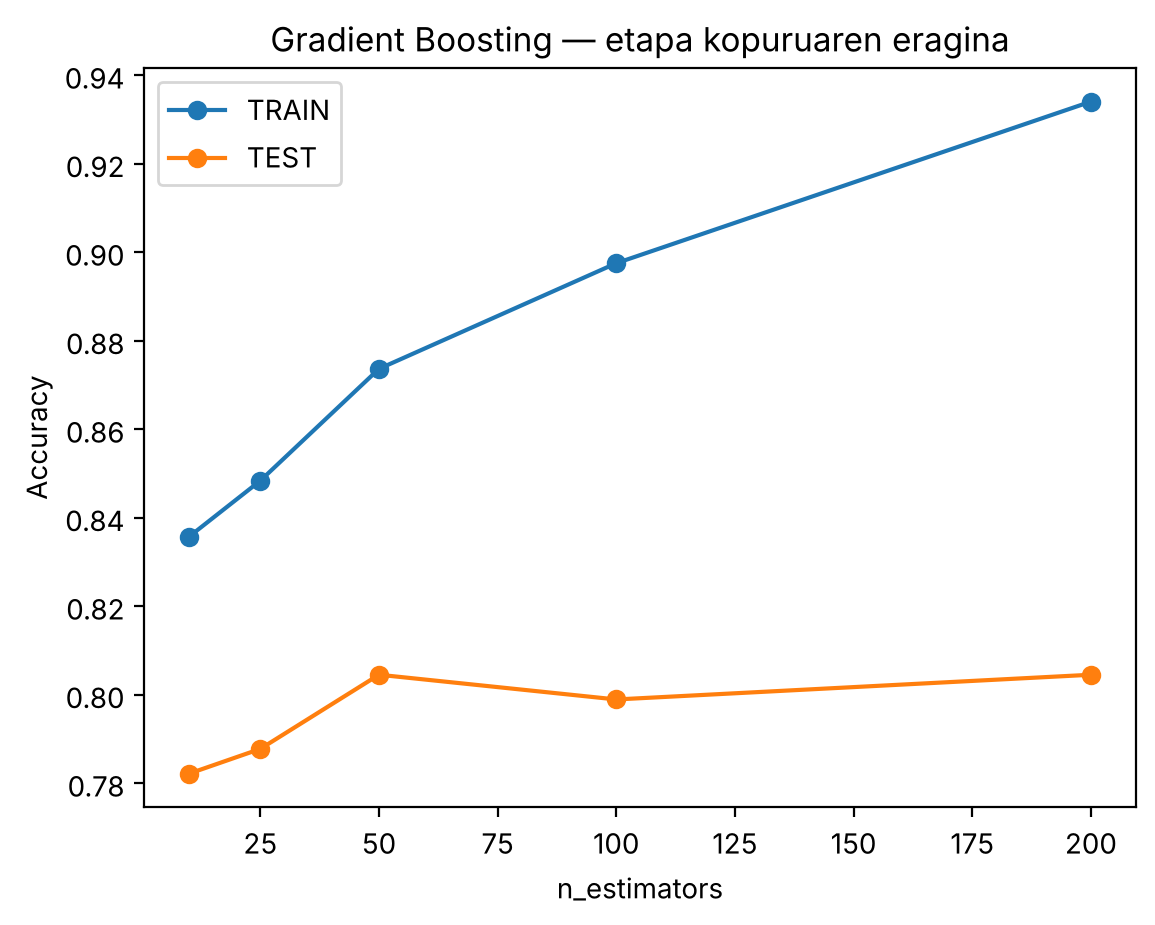

n_estimators= 10  TRAIN=0.836  TEST=0.782
n_estimators= 25  TRAIN=0.848  TEST=0.788
n_estimators= 50  TRAIN=0.874  TEST=0.804
n_estimators=100  TRAIN=0.897  TEST=0.799
n_estimators=200  TRAIN=0.934  TEST=0.804


In [14]:
estimators = [10, 25, 50, 100, 200]

boost_train = []
boost_test = []

for n in estimators:

    modeloa = GradientBoostingClassifier(
        n_estimators=n,
        learning_rate=0.1,
        random_state=42
    )

    modeloa.fit(X_train, y_train)

    boost_train.append(
        modeloa.score(X_train, y_train)
    )

    boost_test.append(
        modeloa.score(X_test, y_test)
    )


plt.plot(
    estimators,
    boost_train,
    marker='o',
    label='TRAIN'
)

plt.plot(
    estimators,
    boost_test,
    marker='o',
    label='TEST'
)

plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.title('Gradient Boosting — etapa kopuruaren eragina')
plt.legend()
plt.show()


for n, tr, te in zip(estimators, boost_train, boost_test):
    print(f'n_estimators={n:3d}  TRAIN={tr:.3f}  TEST={te:.3f}')

**Erantzuna (5.2):** **Ez.** TRAIN etengabe igotzen da (0.836 → 0.934), baina TEST 50 etapatik aurrera **ez da hobetzen** (0.804 → 0.799 → 0.804). Etapa gehiagorekin gap-a handitzen doa (200 etapa: 0.934 vs 0.804): ensemble-a train datuetara gero eta gehiago egokitzen da. Boosting sekuentziala denez, gehiegi entrenatzeak overfitting-a ekar dezake; horregatik `n_estimators` eta `learning_rate` elkarrekin aukeratu behar dira.

# 6 ATALA — Random Forest vs Gradient Boosting 🟢

| | Random Forest | Gradient Boosting |
|---|---|---|
| Oinarrizko ereduak | zuhaitz asko | normalean zuhaitz txiki asko |
| Entrenamendua | independenteago / paraleloan | **sekuentziala** |
| Zuhaitz berriak | ez du aurreko errorea zuzenean jarraitzen | uneko errore/loss-a murrizten saiatzen da |
| Azken emaitza | bozketa / batezbestekoa | zuzenketen konbinazioa |
| Helburu intuitiboa | variance murriztu / egonkortu | errorea progresiboki murriztu |
| Parametro tipikoa | `n_estimators`, `max_features` | `n_estimators`, `learning_rate` |
| Scaling | ez | ez |

Labur:

> **Random Forest = zuhaitz desberdin asko + bozketa**  
> **Gradient Boosting = zuhaitz sekuentzialak + zuzenketa progresiboak**


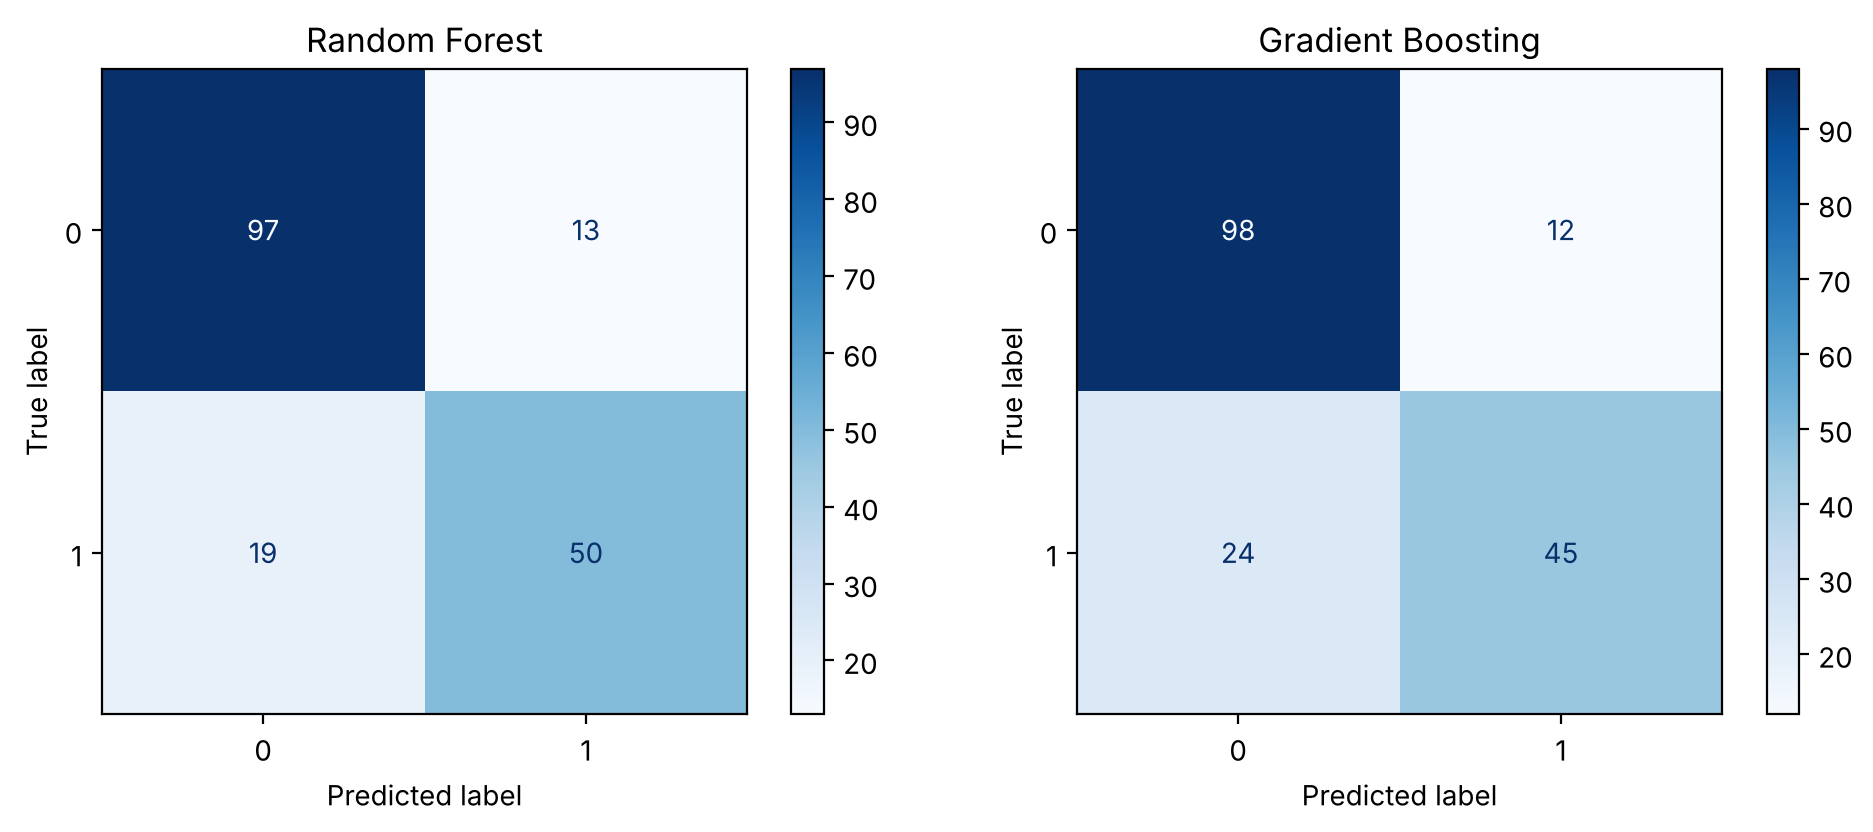

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_pred,
    ax=axes[0],
    cmap='Blues'
)
axes[0].set_title('Random Forest')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    boost_pred,
    ax=axes[1],
    cmap='Blues'
)
axes[1].set_title('Gradient Boosting')

plt.tight_layout()
plt.show()


# 7 ATALA — Ereduak konparatu: zein da egokiena **egoera honetan**? 🟡

Orain 6 sailkatzaile konparatuko ditugu Titanic TEST multzo **berean**:

```text
Decision Tree
KNN
Logistic Regression
SVM RBF
Random Forest
Gradient Boosting
```

Baina atal honetako helburu nagusia EZ da:

> ❌ “algoritmo irabazlea” aurkitzea.

Baizik eta:

> ✅ **esperimentu zehatz batean modeloen portaera konparatzen ikastea.**

---

## ⚠️ Grafikoak ez du ranking unibertsal bat erakusten

Lortuko dugun emaitza baldintza hauen menpe dago:

```text
Titanic dataset hau
+
aukeratutako feature-ak
+
preprocessing hau
+
TRAIN / TEST banaketa hau
(random_state=42)
+
hyperparameter hauek
+
accuracy metrika
```

Horietako zerbait aldatzen badugu, emaitza ere alda daiteke.

Beraz modelo batek barra handiena badu, ez esan:

> ❌ “Modelo hau onena da.”

Esan:

> ✅ **“Esperimentu honetan, konfigurazio honetan eta TEST multzo honetan, modelo honek accuracy altuena lortu du.”**

---

## Konparaketa honen mugak

### 1. TRAIN / TEST split bakarra dugu

Oraingoz datuen banaketa bakarra ikusten ari gara.

```text
random_state=42
```

aldatuko bagenu, score-ak pixka bat alda daitezke.

Aurrerago **cross-validation** erabiliko dugu emaitza sendoagoa den ikusteko.

### 2. Accuracy metrika bakarra erabiltzen dugu

Accuracy-k galdetzen du:

> TEST kasu guztietatik zenbat asmatu?

Baina beste problema batean garrantzitsuagoa izan daiteke:

```text
recall
precision
F1
...
```

Metric-a aldatzen bada, modeloen konparazioa ere alda daiteke.

### 3. Hyperparameter-ak ez daude modu berdinean optimizatuta

Adibidez:

```text
KNN → default parametro asko
SVM → RBF default parametro asko
RF → 100 zuhaitz
Boosting → 100 etapa, learning_rate=0.1
```

Beraz hau **konparaketa didaktikoa** da, ez azken benchmark zientifikoa.

### 4. “Modelo egokia” problemaren beharren araberakoa da

Accuracy ez da irizpide bakarra.

Beste galdera batzuk:

```text
Interpretazioa behar dugu?
Prediction oso azkarra behar dugu?
Datu gutxi edo asko ditugu?
Erlazio linealak dira?
Noise / outlier asko dago?
False Negative-ak oso garestiak dira?
Memoria / entrenamendu denbora mugatua da?
```

> **Ez dago algoritmo irabazle unibertsalik. Problema jakin batean, baldintza jakin batzuetan, modelo batzuk egokiagoak izan daitezke besteak baino.**

---

## Input zuzena modelorako

```text
Decision Tree / Random Forest / Gradient Boosting
→ X_train, X_test
→ scaling ez da behar

KNN / Logistic Regression / SVM
→ X_train_s, X_test_s
→ scaling erabiltzen dugu
```

Horrela aurreko saioetan ikasitako preprocessing arauak mantentzen ditugu.


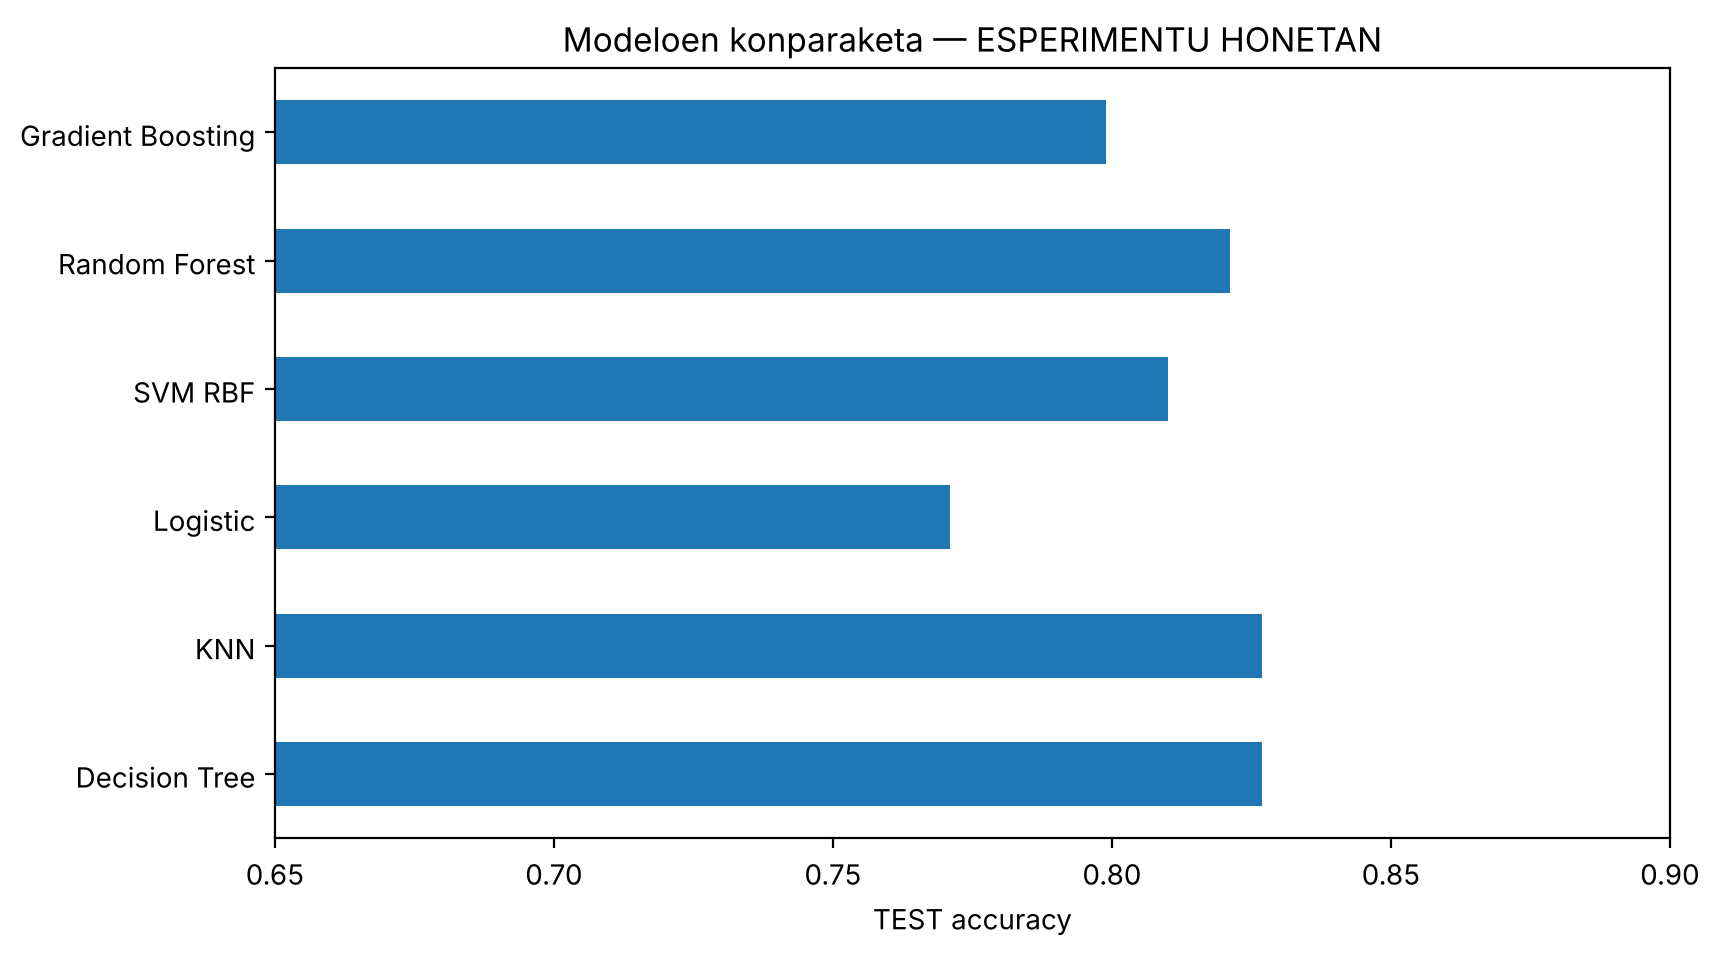

Decision Tree      0.827
KNN                0.827
Logistic           0.771
SVM RBF            0.810
Random Forest      0.821
Gradient Boosting  0.799

⚠️ Hau EZ da ranking unibertsala.
Dataset-a, split-a, preprocessing-a, hyperparameter-ak edo metric-a aldatuz gero, emaitzak ere alda daitezke.


In [16]:
# ------------------------------------------------------------
# 1) MODELOAK
# ------------------------------------------------------------
tree_final = DecisionTreeClassifier(
    random_state=42
)

knn_final = KNeighborsClassifier()

log_final = LogisticRegression(
    max_iter=1000
)

svm_final = SVC(
    kernel='rbf'
)

rf_final = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

boost_final = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)


# ------------------------------------------------------------
# 2) MODELO BAKOITZARI DAGOKION INPUT-A
# ------------------------------------------------------------
# Tree-based:
#   X_train / X_test
#
# Distantzia / koefiziente / marjina sentikorragoak:
#   X_train_s / X_test_s
ereduak = {
    'Decision Tree': (
        tree_final,
        X_train,
        X_test
    ),

    'KNN': (
        knn_final,
        X_train_s,
        X_test_s
    ),

    'Logistic': (
        log_final,
        X_train_s,
        X_test_s
    ),

    'SVM RBF': (
        svm_final,
        X_train_s,
        X_test_s
    ),

    'Random Forest': (
        rf_final,
        X_train,
        X_test
    ),

    'Gradient Boosting': (
        boost_final,
        X_train,
        X_test
    )
}


# ------------------------------------------------------------
# 3) TEST ACCURACY
# ------------------------------------------------------------
emaitzak = {}

for izena, (modeloa, Xtr, Xte) in ereduak.items():

    # Eredua dagokion TRAIN input-arekin entrenatu.
    modeloa.fit(
        Xtr,
        y_train
    )

    # TEST score-a soilik konparaketarako.
    emaitzak[izena] = modeloa.score(
        Xte,
        y_test
    )


# ------------------------------------------------------------
# 4) GRAFIKOA
# ------------------------------------------------------------
# EZ dugu sort_values() erabiltzen.
#
# Zergatik?
# Barra handienetik txikienera ordenatzeak "podium" edo
# ranking unibertsal baten sentsazioa eman dezake.
#
# Ikasi ditugun ordena pedagogikoa mantentzen dugu.
pd.Series(emaitzak).plot(
    kind='barh',
    figsize=(9, 5)
)

plt.xlabel('TEST accuracy')
plt.title(
    'Modeloen konparaketa — ESPERIMENTU HONETAN'
)

plt.xlim(0.65, 0.90)
plt.show()


# Zenbakiak ere erakutsi.
for izena, acc in emaitzak.items():
    print(f'{izena:18s} {acc:.3f}')


print()
print('⚠️ Hau EZ da ranking unibertsala.')
print(
    'Dataset-a, split-a, preprocessing-a, '
    'hyperparameter-ak edo metric-a aldatuz gero, '
    'emaitzak ere alda daitezke.'
)


## 7.1 — Interpretatu emaitza, ez aukeratu “txapelduna” 🧠

Grafikoa exekutatu ondoren, erantzun ahoz edo talde txikietan:

1. **Zein modelok lortu du accuracy altuena esperimentu honetan?**
2. Horrek esan nahi al du modelo hori **beti** onena dela? Zergatik?
3. Zer alda liteke `random_state` / TRAIN-TEST banaketa aldatuko bagenu?
4. Accuracy-ren ordez **recall** lehenetsiko bagenu, aukera bera egingo genukeela ziur al gaude?
5. Bezero batek esango baligu “modeloa azaldu ahal izatea oso garrantzitsua da”, accuracy bakarrik begiratuko genuke?
6. Hyperparameter tuning egin ondoren grafiko berdina aterako dela ziur al gaude?

### Esaldi zuzena

> **“Esperimentu honetan modelo X-k accuracy handiena lortu du.”**

### Saihestu

> **“X da algoritmo onena.”**

Aurrerago:

```text
TRAIN / TEST bakarra
        ↓
cross-validation
        ↓
emaitza sendoagoak

default hyperparameter-ak
        ↓
hyperparameter tuning
        ↓
konparaketa bidezkoagoa
```


### 7.1 Erantzunak

1. Esperimentu honetan **Decision Tree eta KNN-k** lortu dute accuracy altuena (**0.827**, berdinketa), Random Forest (0.821) eta SVM RBF (0.810) oso gertu.
2. **Ez.** Emaitza hau dataset, feature, preprocessing, split (`random_state=42`), hiperparametro eta metrika jakin baten menpe dago. Gainera aldeak oso txikiak dira (179 bidaiariko test-ean, 0.006 ≈ 1 bidaiari).
3. Split-a aldatuta score guztiak aldatuko lirateke, eta **ordena ere alda liteke**, aldeak hain txikiak direnez. Adibidez, Decision Tree mugagabearen TRAIN 0.982 da: variance handia du eta split desberdin batean test txarragoa izan dezake. Cross-validation behar da emaitza sendoagoa izateko.
4. **Ez.** Recall-ek errore mota bat bakarrik neurtzen du (bizirik zeudenak ez detektatzea); modelo batek accuracy altuagoa eta recall baxuagoa izan dezake. Metrika aldatzean aukera ere alda daiteke.
5. **Ez.** Interpretabilitatea garrantzitsua bada, Decision Tree txiki bat edo Logistic Regression (koefizienteak) hobeak izan daitezke accuracy pixka bat baxuagoarekin ere; Random Forest, Boosting edo SVM RBF ulertzeko zailagoak dira.
6. **Ez.** Default parametroekin konparatu dugu; tuning ondoren modelo bakoitzak hobekuntza desberdina izan dezake (adib. Boosting eta SVM-k hiperparametroekiko sentikortasun handia dute), eta grafikoa alda liteke.

# Ondorioak — Sailkapenaren mapa mentala

| Eredua | Ideia nagusia | Scaling |
|---|---|---|
| Decision Tree | split / arauak | Ez |
| KNN | auzokideak / distantziak | **Bai** |
| Logistic Regression | probabilitatea + Log Loss + koefizienteak | Gomendatua |
| SVM | marjina + support vectors + kernel | **Bai** |
| Random Forest | bootstrap + random features + informazioa konbinatu | Ez |
| Gradient Boosting | gradient-ak gidatutako zuzenketa sekuentzialak | Ez |

## Ensemble-en mapa mentala

```text
RANDOM FOREST
TRAIN
↓
bootstrap sample desberdinak
↓
zuhaitz desberdinak
+
split bakoitzeko random feature subset
↓
zuhaitz askoren informazioa konbinatu
↓
prediction


GRADIENT BOOSTING
uneko ensemble-a
↓
prediction + loss
↓
gradient / errore-seinalea
↓
zuhaitz berri bat gehitu
↓
learning_rate-rekin ekarpena kontrolatu
↓
repeat
```

## Eta azken mezua

> **Machine Learning-en ez dugu “algoritmo txapelduna” bilatzen.**

Bilatzen duguna:

> **datu, helburu, metrika eta muga jakin batzuetarako egokia den modeloa.**

Horregatik modeloen konparaketa serio batean aztertu behar ditugu:

```text
dataset-a
feature-ak
preprocessing-a
split / validation estrategia
hyperparameter-ak
metrikak
interpretabilitatea
kostu konputazionala
problemaren benetako beharrak
```
